In [42]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt
import matplotlib
import json5 as json

import uproot

os.environ.get("ROOTSYS")

'/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311'

In [43]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

## Atown's stuff
sys.path.append("..")
from globalsC2 import *
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

import MakeSpectra as MS

In [44]:
## Style setup — PDEStyle colors + larger fonts
import PDEStyle as PS
ms = PS.MyStyleSet()
ms.SetMPLcolors()   # sets matplotlib prop_cycle to PDEStyle colors

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
})

In [45]:
runs, voltages = np.loadtxt(os.path.join(COMP2PATH, "runLists", "bkg_voltage_runs.txt"), unpack=True, delimiter = ",", dtype=int, skiprows=1)

pathAnaJson = "../pyScripts/speAnalysis.json"
pathFileJson = "../pyScripts/files.json"

runs, speValues, rcObjList, tFiles = MS.ExtractSPE(fileConfig=pathFileJson, anaConfig=pathAnaJson, argRunList=runs)

anaCfg = MS.AnalysisConfig(json.load(open(pathAnaJson, 'r')))
for rc, v in zip(rcObjList, voltages):
  rc.mVoltage = v
  # rc.setup_forComparison_np()
  rc.print()
  
  rc.UprootConstructor()


runID: 202204141206
Nevents: 11213.00,   time: 8.54 min
average Rate: 21.88 Hz
chID:0: spe = 87.21 +/- 0.40     maxChi2 = 17.09
chID:1: spe = 93.70 +/- 0.64     maxChi2 = 7.77
chID:2: spe = 93.39 +/- 0.55     maxChi2 = 4.78

runID: 202204141158
Nevents: 10163.00,   time: 5.27 min
average Rate: 32.14 Hz
chID:0: spe = 129.44 +/- 0.57     maxChi2 = 4.28
chID:1: spe = 134.74 +/- 0.98     maxChi2 = 1.83
chID:2: spe = 132.87 +/- 0.67     maxChi2 = 6.68

runID: 202204141138
Nevents: 10089.00,   time: 4.58 min
average Rate: 36.69 Hz
chID:0: spe = 168.29 +/- 0.75     maxChi2 = 3.29
chID:1: spe = 173.60 +/- 1.08     maxChi2 = 13.22
chID:2: spe = 173.43 +/- 0.72     maxChi2 = 3.92

runID: 202204141143
Nevents: 10190.00,   time: 3.95 min
average Rate: 42.99 Hz
chID:0: spe = 205.96 +/- 0.91     maxChi2 = 5.51
chID:1: spe = 212.06 +/- 1.60     maxChi2 = 11.04
chID:2: spe = 213.07 +/- 1.12     maxChi2 = 14.79

runID: 202204141147
Nevents: 10275.00,   time: 3.97 min
average Rate: 43.18 Hz
chID:0: spe

---
### Finger plots and rates

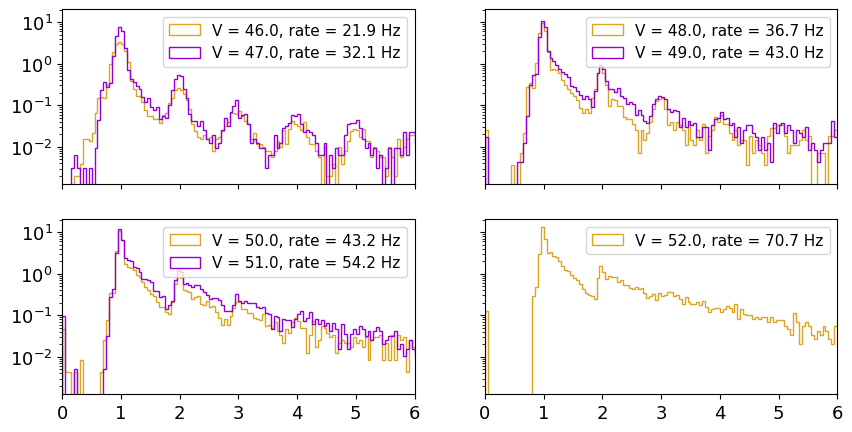

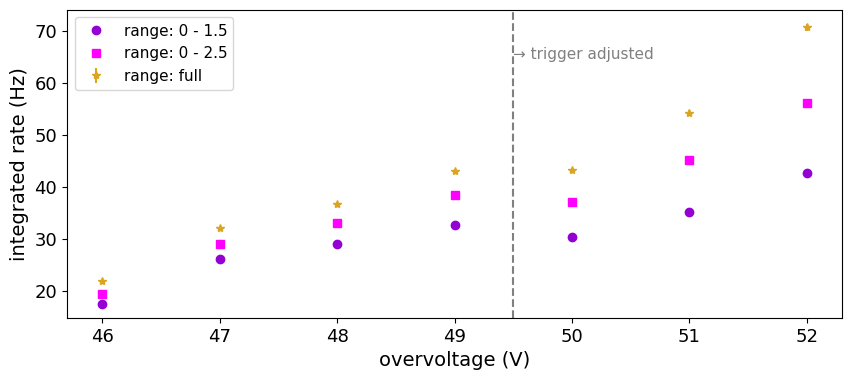

In [46]:
fig, axes = plt.subplots(2, 2, figsize = (10, 5), sharex = True, sharey=True)
axes = axes.flatten()
for rc in rcObjList:
  ax = axes[int(rcObjList.index(rc)//2)]
    
  rc.setup_forComparison_np(Nbins = 200, lowRange=0, maxRange=10, qvar = anaCfg.qvar)
  
  rc.mpl_hist(ax, True, histtype = "step", label = f"V = {rc.mVoltage:0.1f}, rate = {rc.GetRate():0.1f} Hz")
  ax.set_yscale("log")
  ax.legend()
  ax.set_xlim(0, 6)
  
  # ax.vlines(x=1.0, ymin=0.01, ymax=15, color='r', linestyle='--', label='1 PE')
  
def TestRCsum(rc):
  total = np.sum(rc.mBin_rate)
  return total

fig, axes = plt.subplots(1, 1, figsize =(10, 4))
rates = np.array([rc.GetRate() for rc in rcObjList])
ratesError = [rc.GetRateError() for rc in rcObjList]
axes.errorbar(voltages, rates, yerr = ratesError, marker = "*", linestyle = "None", label = "range: full")

ratesLow = [rc.GetNP_integral(0, 1.5) for rc in rcObjList]
axes.plot(voltages, ratesLow, marker = "o", linestyle = "None", label = "range: 0 - 1.5")

ratesMid = [rc.GetNP_integral(0, 2.5) for rc in rcObjList]
axes.plot(voltages, ratesMid, marker = "s", linestyle = "None", label = "range: 0 - 2.5")

axes.axvline(x=49.5, color='gray', linestyle='--')
axes.text(49.5, 0.88, '→ trigger adjusted',
          transform=axes.get_xaxis_transform(),
          color='gray', fontsize=11, va='top')

axes.set_xlabel("overvoltage (V)")
axes.set_ylabel("integrated rate (Hz)")

plt.legend()
plt.show()


---
### SPE values and chi2

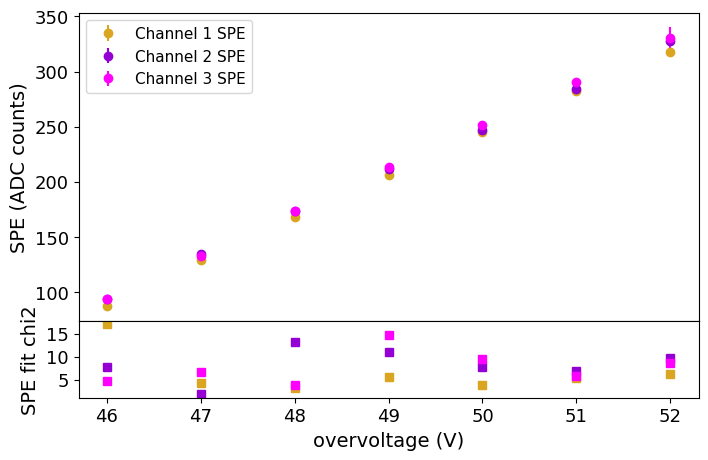

In [47]:
speFig, (speAx, axchi2) = plt.subplots(2, 1, figsize =(8, 5), height_ratios = [4, 1], sharex=True)
plt.subplots_adjust(hspace=0)

## not including horizontal uncertainty in voltage
for ichan in range(anaCfg.nChan):
  spe = np.array([rc.GetChan(ichan).mSpe.spe for rc in rcObjList])
  spe_err = np.array([rc.GetChan(ichan).mSpe.espe for rc in rcObjList])
  spe_chi2 = np.array([rc.GetChan(ichan).mSpe.chi2 for rc in rcObjList])

# plot channel 1 SPE vs voltage
  speAx.errorbar(voltages, spe, yerr = spe_err, marker = "o", linestyle = "None", label = f"Channel {ichan+1} SPE")
  axchi2.plot(voltages, spe_chi2, marker = "s", linestyle = "None", label = f"Channel {ichan+1} SPE chi2")
  
speAx.set_xlabel("overvoltage (V)")
speAx.set_ylabel("SPE (ADC counts)")

axchi2.set_xlabel("overvoltage (V)")
axchi2.set_ylabel("SPE fit chi2")
speAx.legend(loc = 'upper left')
plt.show()

---
### Fitting for breakdown

Fit                      chi2   ndof  chi2/ndof
----------------------------------------------------
Single line            316.68     19     16.667
Three lines             78.06     17      4.592

Parameter               Single line            Three lines
----------------------------------------------------------
m                  39.076 ± 0.100         38.960 ± 0.102  
b (ch 1)           43.665 ± 0.011         43.727 ± 0.012  
b (ch 2)                          —       43.602 ± 0.016  
b (ch 3)                          —       43.575 ± 0.013  
----------------------------------------------------------


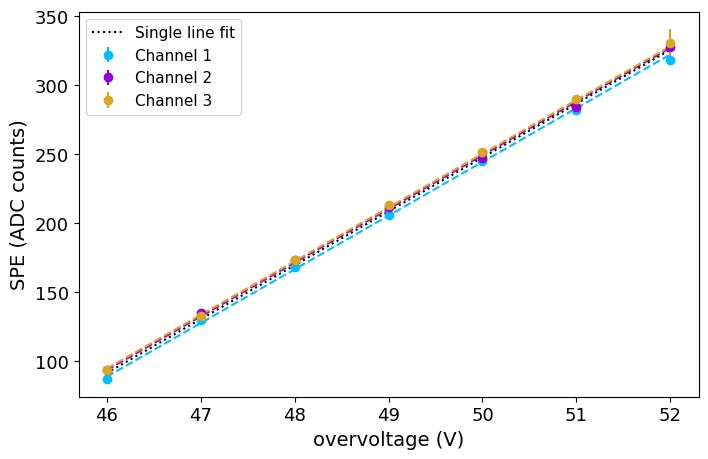

Breakdown voltage avg: 43.665 +/- 0.011


In [48]:
# Simple fits to SPE vs voltage using iminuit
import iminuit
from iminuit import Minuit

# Gather data
voltages = np.array([rc.mVoltage for rc in rcObjList])
nChan = anaCfg.nChan
spe_all = np.concatenate([np.array([rc.GetChan(i).mSpe.spe for rc in rcObjList]) for i in range(nChan)])
spe_err_all = np.concatenate([np.array([rc.GetChan(i).mSpe.espe for rc in rcObjList]) for i in range(nChan)])
volts_all = np.tile(voltages, nChan)
chan_idx = np.concatenate([np.full(len(voltages), i) for i in range(nChan)])

# 1. Fit a single line to all data
def line(x, m, b):
    return m*(x-b)

def chi2_line(m, b):
    return np.sum(((spe_all - line(volts_all, m, b)) / spe_err_all) ** 2)

m1 = Minuit(chi2_line, m=100, b=40)
m1.migrad()

# 2. Fit three lines (shared slope, separate intercepts)
def multi_line(x, chan, m, b0, b1, b2):
    b = np.choose(chan, [b0, b1, b2])
    return m*(x - b)

def chi2_multi(m, b0, b1, b2):
    return np.sum(((spe_all - multi_line(volts_all, chan_idx, m, b0, b1, b2)) / spe_err_all) ** 2)

m2 = Minuit(chi2_multi, m=100, b0=40, b1=40, b2=40)
m2.migrad()

## --- Print fit results ---
ndata = len(spe_all)
ndof1 = ndata - len(m1.values)
ndof2 = ndata - len(m2.values)

print("=" * 52)
print(f"{'Fit':<20} {'chi2':>8}  {'ndof':>5}  {'chi2/ndof':>9}")
print("-" * 52)
print(f"{'Single line':<20} {m1.fval:>8.2f}  {ndof1:>5}  {m1.fval/ndof1:>9.3f}")
print(f"{'Three lines':<20} {m2.fval:>8.2f}  {ndof2:>5}  {m2.fval/ndof2:>9.3f}")
print("=" * 52)

def fmtpv(val, err):
    return f"{val:>8.3f} ± {err:<7.3f}"

print()
w = 22
print(f"{'Parameter':<12} {' Single line':>{w}} {'Three lines':>{w}}")
print("-" * (12 + 2*w + 2))
print(f"{'m':<12} {fmtpv(m1.values['m'],  m1.errors['m']):>{w}} {fmtpv(m2.values['m'],  m2.errors['m']):>{w}}")
print(f"{'b (ch 1)':<12} {fmtpv(m1.values['b'],  m1.errors['b']):>{w}} {fmtpv(m2.values['b0'], m2.errors['b0']):>{w}}")
print(f"{'b (ch 2)':<12} {'—':>{w}} {fmtpv(m2.values['b1'], m2.errors['b1']):>{w}}")
print(f"{'b (ch 3)':<12} {'—':>{w}} {fmtpv(m2.values['b2'], m2.errors['b2']):>{w}}")
print("-" * (12 + 2*w + 2))

# Plot results
fig, ax = plt.subplots(figsize=(8,5))
colors = [ms.cf4.col, ms.lxe.col, ms.air.col]
for i in range(nChan):
    spe = np.array([rc.GetChan(i).mSpe.spe for rc in rcObjList])
    spe_err = np.array([rc.GetChan(i).mSpe.espe for rc in rcObjList])
    ax.errorbar(voltages, spe, yerr=spe_err, marker='o', linestyle='None', color=colors[i], label=f'Channel {i+1}')
    fit_y = m2.values['m'] * (voltages - m2.values[f'b{i}'])
    ax.plot(voltages, fit_y, color=colors[i], linestyle='--')
    
# Plot single line fit
ax.plot(voltages, m1.values['m'] * (voltages - m1.values['b']), color='k', linestyle=':', label='Single line fit')
ax.set_xlabel('overvoltage (V)')
ax.set_ylabel('SPE (ADC counts)')
ax.legend()
plt.show()

print(f"Breakdown voltage avg: {m1.values['b']:0.3f} +/- {m1.errors['b']:0.3f}")

vbr = m1.values['b']


---
### Looking at NCAs (at event level. WRONG)

In [49]:
## load giacomo's data
datV, datCA = np.loadtxt(COMP2PATH+ "/literatureData/giacomoNoise_newVUV4.txt", delimiter=",", skiprows=1, unpack = True)
datV2, datCA2 = np.loadtxt(COMP2PATH+ "/literatureData/giacomoNoise_oldVUV4.txt", delimiter=",", skiprows=1, unpack = True)

46 NCA =  1.93 0.37 0.18
47 NCA =  1.59 0.34 0.18
48 NCA =  1.38 0.38 0.22
49 NCA =  1.5 0.44 0.29
50 NCA =  1.59 0.56 0.39
51 NCA =  1.68 0.66 0.49
52 NCA =  1.7 0.8 0.59


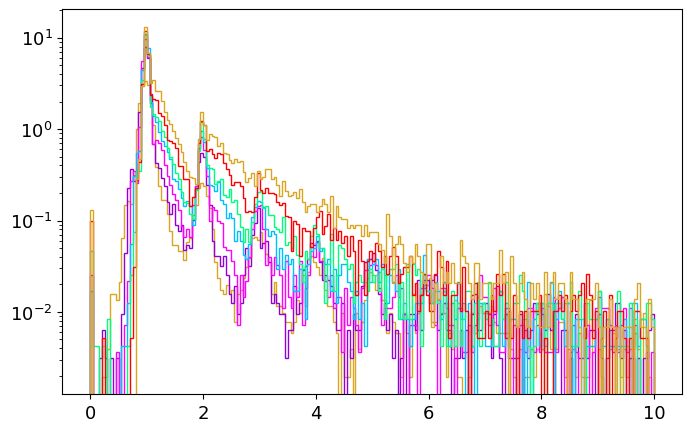

In [58]:
fig, ax = plt.subplots(figsize=(8,5))

ncaMean = []
ncaMeanRestricted = []
ncaHistMean = []
histBounds = (0.5, 4.5)

for rc in rcObjList:
  ## print rc members
  speVals = rc.GetSPEArray(qvar=anaCfg.qvar)
  
  rc.setup_forComparison_np(Nbins = 200, lowRange=0, maxRange=10, qvar = anaCfg.qvar)
  binCenters = 0.5*(rc.mBin_edges[1:] + rc.mBin_edges[:-1])
  histMean = np.sum(binCenters * rc.mBin_rawCounts) / np.sum(rc.mBin_rawCounts)
  
  ncaMean.append(np.mean(speVals)-1.0)
  ncaHistMean.append(histMean-1.0)
  
  restrictedMean = np.mean(speVals[(speVals > histBounds[0]) & (speVals < histBounds[1])])
  ncaMeanRestricted.append(restrictedMean-1.0)
  
  print(rc.mVoltage, "NCA = ", round(np.mean(speVals)-1.0, 2), round(histMean-1.0, 2), round(restrictedMean-1.0,2))
  
  rc.mpl_hist(ax, True, histtype = "step", label = f"V = {rc.mVoltage:0.1f} V")
ax.set_yscale("log")

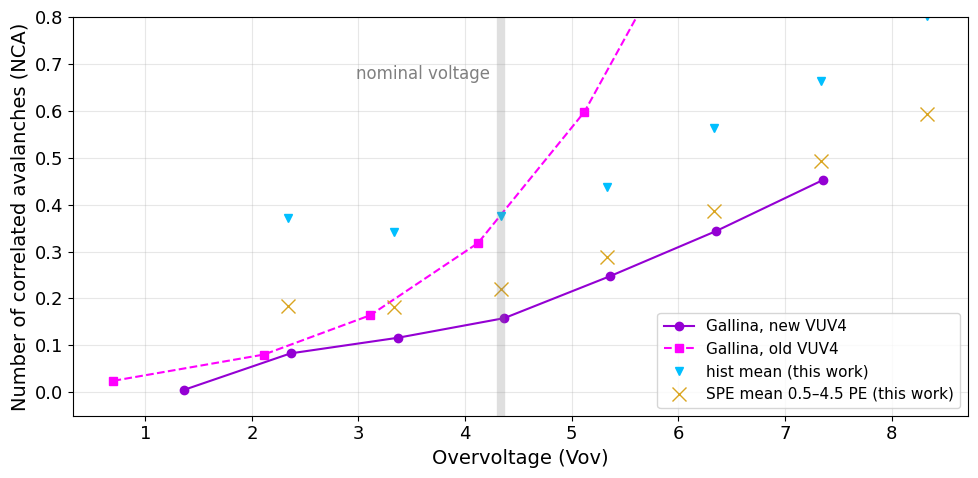

NCA fraction at 48V overvoltage (Gallina new VUV4):  0.1559047194753596
NCA fraction at 48V overvoltage (Our data):  0.21991418795109174


In [71]:
import scipy.interpolate as spInterpolate

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(datV, datCA, marker='o', linestyle='-', color=ms.lxe.col, label='Gallina, new VUV4')
ax.plot(datV2, datCA2, marker='s', linestyle='--', color=ms.lxe2.col, label='Gallina, old VUV4')

ax.plot(voltages - vbr, ncaHistMean, marker='v', linestyle='None', color=ms.cf4.col, label='hist mean (this work)')
ax.plot(voltages - vbr, ncaMeanRestricted, marker='x', linestyle='None', color=ms.air.col,
        label=f'SPE mean {histBounds[0]}–{histBounds[1]} PE (this work)', markersize=10)

ax.axvline(x=48- vbr, color='gray', linestyle='-', linewidth=6, alpha=0.25)
ax.text(48- vbr - 0.1, 0.88, 'nominal voltage',
        transform=ax.get_xaxis_transform(),
        color='gray', fontsize=12, va='top', ha='right')

ax.set_xlabel("Overvoltage (Vov)")
ax.set_ylabel("Number of correlated avalanches (NCA)")
ax.set_ylim(-0.05, 0.8)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fCA = spInterpolate.interp1d(datV, datCA, kind="cubic")
print("NCA fraction at 48V overvoltage (Gallina new VUV4): ", fCA(48.0 - vbr))

fCA_ours = spInterpolate.interp1d(voltages - vbr, ncaMeanRestricted, kind="cubic")
print("NCA fraction at 48V overvoltage (Our data): ", fCA_ours(48.0 - vbr))


In [52]:
## instead only plot for single channel at a time, more realistic
for rc in rcObjList:
  
  allSPE = rc.GetSPEValues(qvar = anaCfg.qvar)
  eventPE = np.sum(allSPE, axis = 1)
  
  a1, a2, a3 = allSPE[:, 0], allSPE[:, 1], allSPE[:, 2]
  upperPEbound = 3.5
  
  # Build mask where a2 == 0 and a3 == 0 (use isclose if values are floats)
  mask1 = (np.isclose(a2, 0) & np.isclose(a3, 0) & (eventPE < upperPEbound))
  mask2 = (np.isclose(a1, 0) & np.isclose(a3, 0) & (eventPE < upperPEbound))
  mask3 = (np.isclose(a1, 0) & np.isclose(a2, 0) & (eventPE < upperPEbound))
  
  # plt.hist(eventPE, bins = 200, range = (0.5, 5.5), label = "event")
  # plt.hist(a1[mask1], bins = 200, range = (0.5, 5.5), histtype = "step", label = "ch1")
  # plt.hist(a2[mask2], bins = 200, range = (0.5, 5.5),histtype = "step", label = "ch2")
  # plt.hist(a3[mask3], bins = 200, range = (0.5, 5.5), histtype = "step", label = "ch3")
  
  mean1 = np.mean(a1[mask1])
  mean2 = np.mean(a2[mask2])
  mean3 = np.mean(a3[mask3])
  
  rc.MeanSoloPE = np.mean(eventPE[eventPE < upperPEbound])
  
  rc.mChannels[0].MeanSoloPE = mean1
  rc.mChannels[1].MeanSoloPE = mean2
  rc.mChannels[2].MeanSoloPE = mean3
  
# plt.yscale("log")

NCA fraction at 48V (new VUV4):  0.1559047194753596


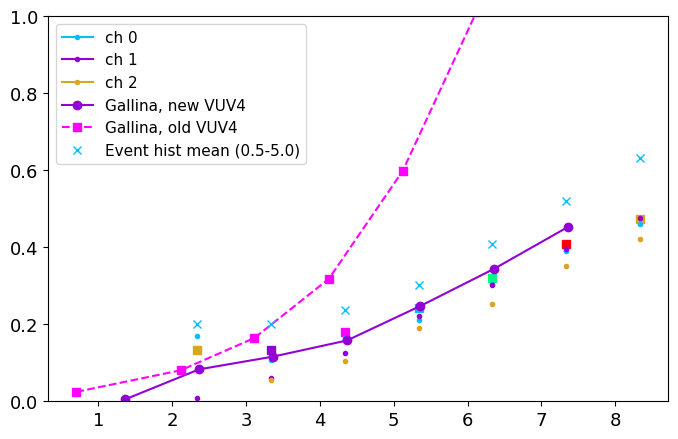

In [53]:
fig, ax = plt.subplots(1, 1, figsize = (8, 5))
chanCols = [ms.cf4.col, ms.lxe.col, ms.air.col]
for rc in rcObjList:
  ax.plot(rc.mVoltage - vbr, rc.MeanSoloPE-1, marker = "s")
  
  for i in range(3):
    lab = f"ch {i}" if rc == rcObjList[0] else None
    ax.plot(rc.mVoltage- vbr, rc.mChannels[i].MeanSoloPE-1, marker = ".", color = chanCols[i], label = lab)

ax.plot(datV, datCA, marker='o', linestyle='-', label='Gallina, new VUV4')
ax.plot(datV2, datCA2, marker='s', linestyle='--', label='Gallina, old VUV4')

# plt.plot(voltages-vbr, ncaMean, marker='^', linestyle='None', label='SPE mean')
# plt.plot(voltages-vbr, ncaHistMean, marker='v', linestyle='None', label='hist mean')
plt.plot(voltages-vbr, ncaMeanRestricted, marker='x', linestyle='None', label=f'Event hist mean ({histBounds[0]}-{histBounds[1]})')

plt.legend()

import scipy.interpolate as spInterpolate
fCA = spInterpolate.interp1d(datV, datCA, kind = "cubic")
print("NCA fraction at 48V (new VUV4): ", fCA(48.0-vbr))

ax.legend()

ax.set_ylim(0, 1.0)
plt.show()


towards higher voltage, values come into agreement, indicating 
that at low voltages, the signal which is out of the pattern is 1. scintillation, 2. we are likely triggering on that channel. It also has lower SPE due to the higher capacitance in the readout